# Resultados de la tesis

**Que se prueba.** K pares de carros (V2V) comparten 15 canales con 15 celulares (CUE). En cada slot, cada carro elige canal y potencia: tiene que vaciar su cola de datos sin danar al CUE de su canal. Cada carro es un agente que aprende (D3QN). La pregunta: **como conviene que compartan lo que aprenden.**

| Metodo | Que hace | Aprende |
|---|---|---|
| DTE | Cada carro aprende solo | Si |
| FedAvg | Una torre promedia los modelos de todos los carros | Si |
| **Gossip** (la propuesta) | Cada carro promedia su modelo con los de sus vecinos, sin torre | Si |
| Greedy | Potencia maxima en el canal menos interferido (referencia del paper) | No |
| Regla de umbral | Regla escrita a mano: enlace fuerte transmite, enlace debil espera a que se llene su cola | No (techo de referencia) |

**Como se mide.** La recompensa de la Ec. 22 del paper (tasa del CUE + cola + confiabilidad; mas alto es mejor), promedio del ultimo 10 % de 2000 episodios, 3 semillas por caso, K = 5 a 30.

**Dos entrenamientos.** `propia`: cada agente aprende de su propia recompensa (su cola, su confiabilidad y el CUE de su canal). `paper`: todos aprenden de la recompensa compartida, como en el paper. Los dos se miden con la misma Ec. 22.

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.insert(0, "..")  # v2v/, para importar analysis.py y plots.py
from analysis import (
    convergence_episode,
    episodes_to_final_gain,
    final_values,
    load_runs,
    per_episode_means,
    summarize_by_k,
)
from plots import (
    EXPECTED_KS,
    METHODS,
    REFERENCE,
    method_label,
    plot_vs_k,
    use_thesis_style,
)

# Los barridos quedan en runs/<barrido>/k<K>/ (make run-<metodo> SWEEP=<barrido>; make pull-runs los trae).
RUNS_ROOT = Path(os.environ.get("V2V_RUNS_ROOT", "../runs"))
FIG_DIR = Path(os.environ.get("V2V_FIG_DIR", "../runs/figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
SWEEPS = ["propia", "paper"]
ORDER = ["umbral", "greedy", "dte", "fedavg", "gossip"]
LEARNERS = ["dte", "fedavg", "gossip"]
FLOOR_EPISODE = 1200  # epsilon llega a su piso al 60 % de los 2000 episodios: ahi termina la exploracion
use_thesis_style()


def load_sweep(sweep):
    # Un metodo a la vez: los CSV crudos de un barrido entero no caben comodos en memoria.
    return pd.concat(
        [per_episode_means(load_runs(RUNS_ROOT / sweep, methods=[m])) for m in ORDER],
        ignore_index=True,
    )


episodes = {
    sweep: load_sweep(sweep) for sweep in SWEEPS
}  # una fila por corrida y episodio
final = pd.concat(
    {sweep: final_values(episodes[sweep]) for sweep in SWEEPS}, names=["sweep"]
)  # una fila por corrida

seeds = final.groupby(["sweep", "method", "k"]).size().unstack("k")
assert (seeds == 3).all().all(), f"faltan corridas:\n{seeds}"
print(f"{len(final)} corridas: 2 barridos x 5 metodos x 6 valores de K x 3 semillas.")

180 corridas: 2 barridos x 5 metodos x 6 valores de K x 3 semillas.


In [ ]:
def means(sweep, metric):
    # Media entre semillas: una fila por K, una columna por metodo.
    return final.loc[sweep][metric].groupby(["k", "method"]).mean().unstack()


def table(sweep, metric, fmt="{:.0f}", scale=1.0, methods=ORDER):
    # Media ± desviacion entre las 3 semillas.
    values = final.loc[sweep][metric] * scale
    grouped = values.groupby(["k", "method"])
    cells = (
        grouped.mean().unstack().map(fmt.format)
        + " ± "
        + grouped.std().unstack().map(fmt.format)
    )
    return (
        cells[methods].rename(columns=method_label).rename_axis(index="K", columns=None)
    )


def wins_table(sweep, others=("fedavg", "dte", "greedy")):
    # Gossip menos cada otro metodo, y en cuantas de las 3 semillas gana gossip.
    rewards = final.loc[sweep]["reward"].unstack("method")  # filas (K, semilla)
    columns = {}
    for other in others:
        diff = (rewards["gossip"] - rewards[other]).groupby("k")
        columns[(f"Gossip vs {method_label(other)}", "Diferencia")] = diff.mean().round(
            0
        )
        columns[(f"Gossip vs {method_label(other)}", "Semillas")] = diff.apply(
            lambda d: f"{(d > 0).sum()} de {d.size}"
        )
    return pd.DataFrame(columns).rename_axis(index="K")

## 1. Quien obtiene mas recompensa (`propia`)

,Regla de umbral,Greedy,DTE (sin federar),FedAvg,Gossip
K,,,,,
5,7215 ± 111,6959 ± 77,6554 ± 196,6607 ± 113,6492 ± 172
10,6948 ± 217,5602 ± 237,5403 ± 274,5315 ± 594,5775 ± 152
15,6201 ± 173,3486 ± 86,4095 ± 175,3689 ± 371,4645 ± 144
20,4997 ± 178,879 ± 85,1993 ± 401,1685 ± 192,3402 ± 226
25,3396 ± 73,-1768 ± 99,-441 ± 103,-209 ± 347,1545 ± 331
30,1694 ± 123,-4396 ± 109,-2762 ± 269,-484 ± 305,-788 ± 325


Mejor metodo que aprende:  K=5 FedAvg, K=10 Gossip, K=15 Gossip, K=20 Gossip, K=25 Gossip, K=30 FedAvg
Mejor sin la regla:        K=5 Greedy, K=10 Gossip, K=15 Gossip, K=20 Gossip, K=25 Gossip, K=30 FedAvg


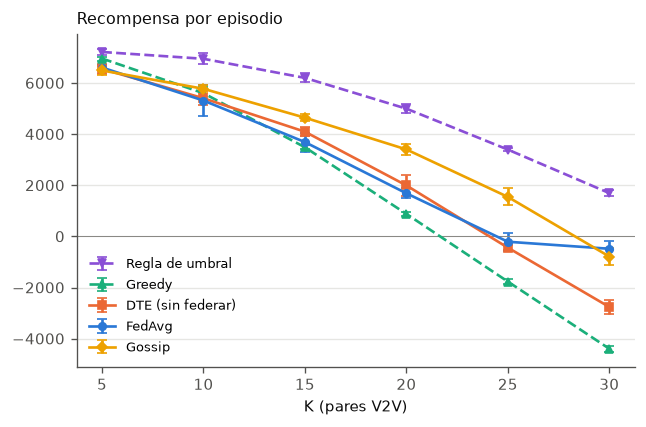

In [ ]:
display(table("propia", "reward"))
reward = means("propia", "reward")
print(
    "Mejor metodo que aprende:  "
    + ", ".join(
        f"K={k} {method_label(m)}" for k, m in reward[LEARNERS].idxmax(axis=1).items()
    )
)
print(
    "Mejor sin la regla:        "
    + ", ".join(
        f"K={k} {method_label(m)}"
        for k, m in reward[["greedy", *LEARNERS]].idxmax(axis=1).items()
    )
)

fig, ax = plt.subplots(figsize=(6, 3.6))
plot_vs_k(ax, summarize_by_k(final.loc["propia"]), "reward", ORDER)
ax.axhline(0, color=REFERENCE, linewidth=0.6)
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "resultados_recompensa_vs_k.pdf")
plt.show()

## 2. Gossip gana en todas las semillas?
Diferencia de recompensa (promedio de las 3 semillas) y en cuantas semillas gana gossip.

In [4]:
display(wins_table("propia"))

Gossip vs FedAvg          Gossip vs DTE (sin federar)           \
         Diferencia Semillas                  Diferencia Semillas   
K                                                                   
5            -115.0   1 de 3                       -62.0   1 de 3   
10            459.0   3 de 3                       372.0   3 de 3   
15            956.0   3 de 3                       550.0   3 de 3   
20           1717.0   3 de 3                      1409.0   3 de 3   
25           1754.0   3 de 3                      1986.0   3 de 3   
30           -304.0   1 de 3                      1974.0   3 de 3   

   Gossip vs Greedy           
         Diferencia Semillas  
K                             
5            -467.0   0 de 3  
10            172.0   3 de 3  
15           1159.0   3 de 3  
20           2523.0   3 de 3  
25           3312.0   3 de 3  
30           3608.0   3 de 3

## 3. Por que gana gossip: no olvida al terminar la exploracion
Hasta el episodio 1200 (linea punteada) los agentes todavia exploran; despues solo usan lo aprendido. Curvas: promedio de las 3 semillas, media movil de 50 episodios.

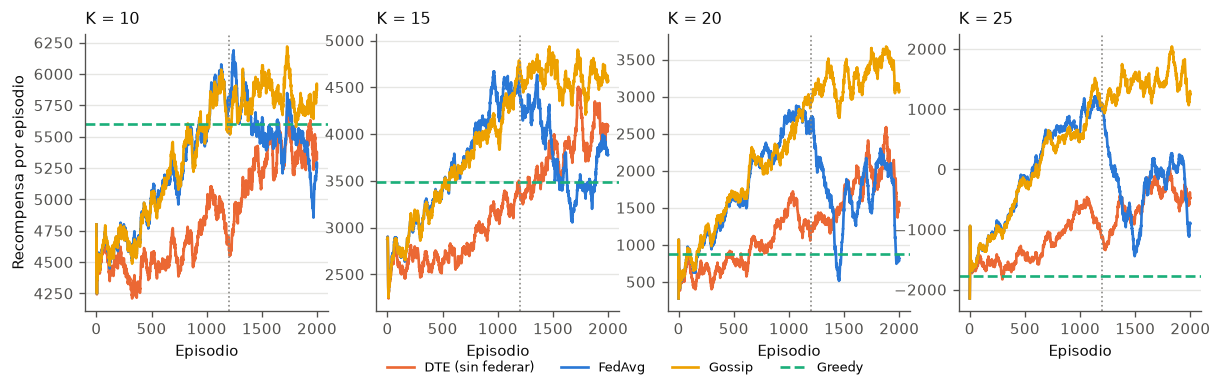

Recompensa perdida desde el mejor tramo hasta el final (promedio de semillas):


,DTE (sin federar),FedAvg,Gossip
K,,,
5,0.0,105.0,167.0
10,155.0,551.0,154.0
15,13.0,922.0,140.0
20,73.0,1047.0,55.0
25,208.0,1270.0,93.0
30,157.0,420.0,787.0


In [ ]:
SHOW_KS = [10, 15, 20, 25]
learning = episodes["propia"]
curve = learning.groupby(["method", "k", "episode"])[
    "reward"
].mean()  # promedio de semillas

fig, axes = plt.subplots(1, len(SHOW_KS), figsize=(12, 3), sharex=True)
for ax, k in zip(axes, SHOW_KS):
    for method in LEARNERS:
        smooth = curve.loc[(method, k)].rolling(50, min_periods=1).mean()
        style = METHODS[method]
        ax.plot(smooth.index, smooth.values, color=style["color"], label=style["label"])
    ax.axhline(
        reward.loc[k, "greedy"],
        color=METHODS["greedy"]["color"],
        linestyle="--",
        label="Greedy",
    )
    ax.axvline(FLOOR_EPISODE, color=REFERENCE, linestyle=":", linewidth=1)
    ax.set_title(f"K = {k}")
    ax.set_xlabel("Episodio")
axes[0].set_ylabel("Recompensa por episodio")
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.1),
    fontsize=8,
)
fig.savefig(FIG_DIR / "resultados_curvas_aprendizaje.pdf")
plt.show()

# Cuanto pierde cada corrida: su mejor tramo de 200 episodios menos su tramo final (los ultimos 200).
by_run = learning.set_index("episode").groupby(["method", "k", "seed"])["reward"]
lost = by_run.apply(
    lambda r: r.groupby(r.index // 200).mean().max() - r.iloc[-200:].mean()
)
drop = lost.groupby(["k", "method"]).mean().unstack()[LEARNERS]
print("Recompensa perdida desde el mejor tramo hasta el final (promedio de semillas):")
display(drop.rename(columns=method_label).rename_axis(index="K", columns=None).round(0))

## 4. Velocidad de convergencia
Li et al. (Fig. 10) miran cuantos episodios tarda la recompensa en estabilizarse. Aqui: el episodio en que la media movil de 50 episodios llega al **90 % de la mejora** de la corrida (de su arranque, los primeros 50 episodios, a su valor final). Menos es mas rapido.

,DTE (sin federar),FedAvg,Gossip
K,,,
5,846.0,550.0,426.0
10,1143.0,562.0,765.0
15,1441.0,455.0,937.0
20,1390.0,458.0,1170.0
25,974.0,411.0,1080.0
30,848.0,796.0,712.0


Con un criterio estricto (quedarse a ±5 % de su valor final) se estabilizan 19 de 54 corridas, ninguna antes del episodio 1789: las curvas se mueven hasta casi el final.


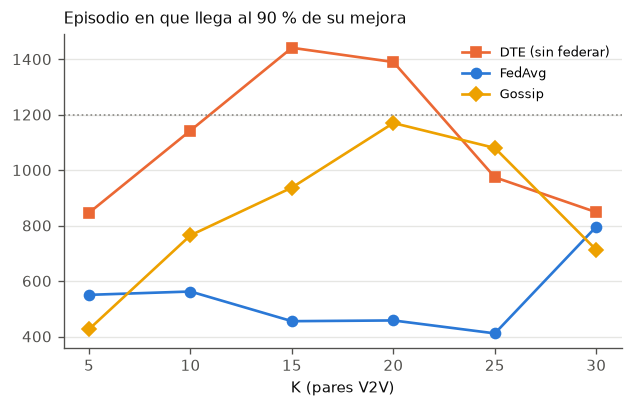

In [ ]:
learner_runs = learning[learning["method"].isin(LEARNERS)].groupby(
    ["method", "k", "seed"]
)["reward"]
to_gain = learner_runs.apply(lambda r: episodes_to_final_gain(r.to_numpy()))
settled = learner_runs.apply(
    lambda r: convergence_episode(r.to_numpy())
)  # se queda a ±5 % de su valor final
speed = to_gain.groupby(["k", "method"]).mean().unstack()[LEARNERS]
display(
    speed.rename(columns=method_label).rename_axis(index="K", columns=None).round(0)
)
if to_gain.isna().any():
    print(
        f"{to_gain.isna().sum()} corridas terminan sin mejorar y quedan fuera del promedio."
    )
print(
    f"Con un criterio estricto (quedarse a ±5 % de su valor final) se estabilizan {settled.notna().sum()} de "
    f"{settled.size} corridas, ninguna antes del episodio {settled.min():.0f}: las curvas se mueven hasta casi el final."
)

fig, ax = plt.subplots(figsize=(6, 3.4))
for method in LEARNERS:
    style = METHODS[method]
    ax.plot(
        speed.index,
        speed[method],
        color=style["color"],
        marker=style["marker"],
        label=style["label"],
    )
ax.axhline(FLOOR_EPISODE, color=REFERENCE, linestyle=":", linewidth=1)
ax.set_xticks(EXPECTED_KS)
ax.set_xlabel("K (pares V2V)")
ax.set_title("Episodio en que llega al 90 % de su mejora")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "resultados_convergencia.pdf")
plt.show()

## 5. Calidad de servicio (`propia`)
- **Tasa CUE:** lo que le queda al celular; mas alto es mejor.
- **Outage:** % de slots en que el enlace V2V no cumple la confiabilidad (callarse cuenta como outage); mas bajo es mejor.
- **Delay:** retardo medio de la cola V2V; el limite es 100 ms.

In [7]:
print("Tasa CUE (Mbps)")
display(table("propia", "cue_rate_mbps", fmt="{:.2f}"))
print("Outage (%)")
display(table("propia", "outage_rate", scale=100))
print("Delay V2V (ms)")
display(table("propia", "v2v_delay_ms", fmt="{:.1f}"))

Tasa CUE (Mbps)


,Regla de umbral,Greedy,DTE (sin federar),FedAvg,Gossip
K,,,,,
5,7.71 ± 0.02,6.57 ± 0.01,7.38 ± 0.06,7.63 ± 0.08,7.61 ± 0.06
10,6.90 ± 0.04,5.05 ± 0.01,6.04 ± 0.47,6.86 ± 0.13,6.65 ± 0.16
15,6.18 ± 0.01,3.98 ± 0.00,4.91 ± 0.42,6.43 ± 0.18,5.81 ± 0.09
20,5.56 ± 0.04,3.22 ± 0.00,3.57 ± 0.31,6.14 ± 0.04,5.37 ± 0.12
25,5.03 ± 0.03,2.69 ± 0.01,2.55 ± 0.20,5.80 ± 0.18,5.04 ± 0.25
30,4.59 ± 0.04,2.33 ± 0.01,2.17 ± 0.15,4.99 ± 0.33,4.93 ± 0.45


Outage (%)


,Regla de umbral,Greedy,DTE (sin federar),FedAvg,Gossip
K,,,,,
5,63 ± 1,26 ± 0,56 ± 2,62 ± 2,61 ± 3
10,64 ± 1,34 ± 1,54 ± 7,66 ± 3,62 ± 3
15,65 ± 0,43 ± 0,56 ± 4,71 ± 3,63 ± 1
20,67 ± 0,50 ± 0,54 ± 3,75 ± 0,67 ± 1
25,68 ± 0,57 ± 0,54 ± 1,77 ± 2,71 ± 2
30,69 ± 0,64 ± 0,59 ± 1,74 ± 2,75 ± 3


Delay V2V (ms)


,Regla de umbral,Greedy,DTE (sin federar),FedAvg,Gossip
K,,,,,
5,34.1 ± 0.9,0.0 ± 0.0,19.5 ± 1.1,27.3 ± 2.6,29.7 ± 4.8
10,34.9 ± 0.8,0.0 ± 0.0,16.6 ± 6.0,23.7 ± 3.1,25.3 ± 3.3
15,34.9 ± 0.3,0.0 ± 0.0,14.3 ± 3.6,25.3 ± 3.7,20.6 ± 1.7
20,35.4 ± 0.5,0.0 ± 0.0,9.8 ± 2.0,25.0 ± 1.3,23.7 ± 2.7
25,35.2 ± 0.5,0.1 ± 0.0,5.7 ± 0.7,29.4 ± 3.9,24.6 ± 3.5
30,35.4 ± 0.6,0.1 ± 0.0,5.3 ± 0.6,29.6 ± 4.0,27.2 ± 5.1


## 6. Costo de comunicacion
- **FedAvg:** cada 50 slots, todos suben su modelo a la torre y bajan el promedio.
- **Gossip:** cada 50 slots, cada carro recibe el modelo de cada vecino a 300 m o menos.

In [ ]:
models = means("propia", "comm_models")
busiest = means("propia", "comm_max_load")
comm = pd.DataFrame(
    {
        ("Modelos enviados por episodio", "FedAvg"): models["fedavg"],
        ("Modelos enviados por episodio", "Gossip"): models["gossip"],
        ("Modelos enviados por episodio", "Gossip / FedAvg"): models["gossip"]
        / models["fedavg"],
        ("Nodo mas cargado", "FedAvg (la torre)"): busiest["fedavg"],
        ("Nodo mas cargado", "Gossip (un carro)"): busiest["gossip"],
        ("Nodo mas cargado", "Gossip / FedAvg"): busiest["gossip"] / busiest["fedavg"],
    }
).rename_axis(index="K")
display(comm.round(2))

Modelos enviados por episodio                          Nodo mas cargado  \
                          FedAvg  Gossip Gossip / FedAvg FedAvg (la torre)   
K                                                                            
5                           40.0   21.39            0.53              40.0   
10                          80.0   96.73            1.21              80.0   
15                         120.0  224.83            1.87             120.0   
20                         160.0  406.35            2.54             160.0   
25                         200.0  641.20            3.21             200.0   
30                         240.0  935.51            3.90             240.0   

                                      
   Gossip (un carro) Gossip / FedAvg  
K                                     
5              14.43            0.36  
10             33.49            0.42  
15             51.67            0.43  
20             69.59            0.43  
25             86.40            0.43  
30            104.24            0.43

## 7. Que aporta la recompensa propia
Los mismos metodos entrenados con la recompensa compartida del paper (`paper`). Cada celda: `paper` -> `propia` (ganancia).

,DTE (sin federar),FedAvg,Gossip,Greedy
K,,,,
5,6220 -> 6554 (+334),6186 -> 6607 (+421),6248 -> 6492 (+244),6959
10,4896 -> 5403 (+507),4710 -> 5315 (+605),4774 -> 5775 (+1000),5602
15,3285 -> 4095 (+810),2551 -> 3689 (+1138),2879 -> 4645 (+1766),3486
20,1408 -> 1993 (+585),1702 -> 1685 (-17),2083 -> 3402 (+1319),879
25,-882 -> -441 (+441),-1682 -> -209 (+1473),-2181 -> 1545 (+3726),-1768
30,-2701 -> -2762 (-61),-2887 -> -484 (+2403),-2950 -> -788 (+2162),-4396


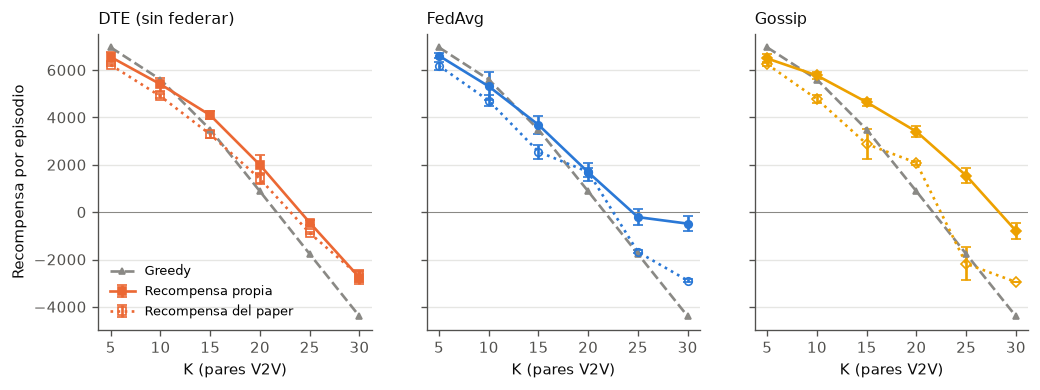

Con la recompensa del paper:


Gossip vs FedAvg         
         Diferencia Semillas
K                           
5              62.0   2 de 3
10             64.0   2 de 3
15            328.0   3 de 3
20            380.0   2 de 3
25           -499.0   1 de 3
30            -63.0   0 de 3

In [ ]:
reward_paper = means("paper", "reward")
gain = pd.DataFrame(
    {
        method_label(m): [
            f"{reward_paper.loc[k, m]:.0f} -> {reward.loc[k, m]:.0f} ({reward.loc[k, m] - reward_paper.loc[k, m]:+.0f})"
            for k in reward.index
        ]
        for m in LEARNERS
    },
    index=pd.Index(reward.index, name="K"),
).assign(Greedy=reward["greedy"].round(0).astype(int))
display(gain)

stats = {
    sweep: final.loc[sweep]["reward"].groupby(["method", "k"]).agg(["mean", "std"])
    for sweep in SWEEPS
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, method in zip(axes, LEARNERS):
    style = METHODS[method]
    for sweep, linestyle, fill, label in (
        ("propia", "-", "full", "Recompensa propia"),
        ("paper", ":", "none", "Recompensa del paper"),
    ):
        s = stats[sweep].loc[method]
        ax.errorbar(
            s.index,
            s["mean"],
            yerr=s["std"],
            color=style["color"],
            linestyle=linestyle,
            marker=style["marker"],
            fillstyle=fill,
            markersize=4.5,
            capsize=3,
            label=label,
        )
    ax.plot(
        reward.index,
        reward["greedy"],
        color=REFERENCE,
        linestyle="--",
        marker="^",
        markersize=4,
        label="Greedy",
    )
    ax.axhline(0, color=REFERENCE, linewidth=0.6)
    ax.set_xticks(EXPECTED_KS)
    ax.set_xlabel("K (pares V2V)")
    ax.set_title(style["label"])
axes[0].set_ylabel("Recompensa por episodio")
axes[0].legend(loc="lower left", fontsize=7.5)
fig.savefig(FIG_DIR / "resultados_recompensa_propia_vs_paper.pdf")
plt.show()

print("Con la recompensa del paper:")
display(wins_table("paper", others=("fedavg",)))

## Conclusiones
1. **Gossip con recompensa propia es el mejor metodo que aprende con K = 10 a 25**, y le gana a DTE y a Greedy en las 3 semillas desde K = 10.
2. **Gana porque no olvida:** mientras exploran, FedAvg y gossip aprenden casi igual; al terminar la exploracion FedAvg pierde parte de lo aprendido y gossip se mantiene.
3. **Limites:** con K = 5 Greedy es mejor (casi no hay interferencia que coordinar); con K = 30 FedAvg queda un poco arriba de gossip.
4. **Calidad de servicio:** gossip protege la tasa del CUE mucho mejor que Greedy y DTE; a cambio, sus carros se callan mas (mas outage) y dejan mas datos en cola, siempre bajo el limite de 100 ms.
5. **Comunicacion:** gossip no necesita torre y su carro mas cargado mueve menos de la mitad que la torre de FedAvg, pero en total manda mas modelos.
6. **La ventaja es de la combinacion:** con la recompensa compartida del paper, gossip no se destaca.
7. **Hay margen:** ningun metodo que aprende alcanza la regla de umbral.
8. **Convergencia:** ninguna curva se estabiliza del todo antes del final. Mientras exploran, gossip y FedAvg aprenden al mismo ritmo y mas rapido que DTE; FedAvg llega antes al 90 % de su mejora, pero esa mejora es menor.

La celda siguiente comprueba cada conclusion con los datos.

In [ ]:
reward_runs = {
    sweep: final.loc[sweep]["reward"].unstack("method") for sweep in SWEEPS
}  # filas (K, semilla)
cue = means("propia", "cue_rate_mbps")
outage = means("propia", "outage_rate")
delay = means("propia", "v2v_delay_ms")


def all_seeds(sweep, a, b, k):
    runs = reward_runs[sweep].loc[k]
    return bool((runs[a] > runs[b]).all())


checks = {
    "1. Gossip es el mejor que aprende con K = 10 a 25": all(
        reward.loc[k, LEARNERS].idxmax() == "gossip" for k in [10, 15, 20, 25]
    ),
    "1. Gossip le gana a DTE y a Greedy en las 3 semillas desde K = 10": all(
        all_seeds("propia", "gossip", other, k)
        for other in ["dte", "greedy"]
        for k in EXPECTED_KS[1:]
    ),
    "2. FedAvg pierde mas que gossip despues de su mejor tramo (K = 15 a 25)": all(
        drop.loc[k, "fedavg"] > drop.loc[k, "gossip"] for k in [15, 20, 25]
    ),
    "3. Con K = 5 Greedy le gana a todos los que aprenden": reward.loc[5, "greedy"]
    > reward.loc[5, LEARNERS].max(),
    "3. Con K = 30 FedAvg queda arriba de gossip": reward.loc[30, "fedavg"]
    > reward.loc[30, "gossip"],
    "4. Gossip tiene mas tasa CUE que Greedy y DTE desde K = 10": bool(
        (cue.loc[10:, "gossip"] > cue.loc[10:, ["greedy", "dte"]].max(axis=1)).all()
    ),
    "4. Gossip tiene mas outage que Greedy en todos los K": bool(
        (outage["gossip"] > outage["greedy"]).all()
    ),
    "4. El delay de todos los metodos queda bajo 100 ms": bool(
        (delay < 100).all().all()
    ),
    "5. El carro mas cargado de gossip mueve menos de la mitad que la torre": bool(
        (busiest["gossip"] / busiest["fedavg"] < 0.5).all()
    ),
    "5. Gossip manda mas modelos en total desde K = 10": bool(
        (models.loc[10:, "gossip"] > models.loc[10:, "fedavg"]).all()
    ),
    "6. Con la recompensa del paper, gossip le gana a FedAvg en las 3 semillas en a lo sumo 2 valores de K": sum(
        all_seeds("paper", "gossip", "fedavg", k) for k in EXPECTED_KS
    )
    <= 2,
    "6. La recompensa propia mejora a gossip en todos los K": bool(
        (reward["gossip"] > reward_paper["gossip"]).all()
    ),
    "7. La regla de umbral queda arriba de todos los que aprenden": bool(
        (reward["umbral"] > reward[LEARNERS].max(axis=1)).all()
    ),
    "8. Con el criterio estricto, ninguna corrida se estabiliza antes del episodio 1750": bool(
        settled.dropna().min() >= 1750
    ),
    "8. Antes del episodio 1000, FedAvg y gossip difieren en promedio menos del 5 % de la mejora de gossip (K = 10 a 30)": all(
        abs(
            (
                curve.loc[("fedavg", k)].loc[:999] - curve.loc[("gossip", k)].loc[:999]
            ).mean()
        )
        < 0.05 * (reward.loc[k, "gossip"] - curve.loc[("gossip", k)].iloc[:50].mean())
        for k in EXPECTED_KS[1:]
    ),
    "8. Mientras exploran (episodios 200 a 1199), gossip va por encima de DTE (K = 10 a 30)": all(
        (
            curve.loc[("gossip", k)].loc[200:1199] - curve.loc[("dte", k)].loc[200:1199]
        ).mean()
        > 0
        for k in EXPECTED_KS[1:]
    ),
    "8. FedAvg llega antes que gossip al 90 % de su mejora, pero termina mas abajo (K = 10 a 25)": all(
        speed.loc[k, "fedavg"] < speed.loc[k, "gossip"]
        and reward.loc[k, "fedavg"] < reward.loc[k, "gossip"]
        for k in [10, 15, 20, 25]
    ),
}
for text, ok in checks.items():
    print(("OK     " if ok else "FALLA  ") + text)

OK     1. Gossip es el mejor que aprende con K = 10 a 25
OK     1. Gossip le gana a DTE y a Greedy en las 3 semillas desde K = 10
OK     2. FedAvg pierde mas que gossip despues de su mejor tramo (K = 15 a 25)
OK     3. Con K = 5 Greedy le gana a todos los que aprenden
OK     3. Con K = 30 FedAvg queda arriba de gossip
OK     4. Gossip tiene mas tasa CUE que Greedy y DTE desde K = 10
OK     4. Gossip tiene mas outage que Greedy en todos los K
OK     4. El delay de todos los metodos queda bajo 100 ms
OK     5. El carro mas cargado de gossip mueve menos de la mitad que la torre
OK     5. Gossip manda mas modelos en total desde K = 10
OK     6. Con la recompensa del paper, gossip le gana a FedAvg en las 3 semillas en a lo sumo 2 valores de K
OK     6. La recompensa propia mejora a gossip en todos los K
OK     7. La regla de umbral queda arriba de todos los que aprenden
OK     8. Con el criterio estricto, ninguna corrida se estabiliza antes del episodio 1750
OK     8. Antes del episodio 100